<a href="https://colab.research.google.com/github/nickkraus52/MachineLearning/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dataset Import and Observations
In this code cell I import the dataset and other important modules. I then ran head(), info(), and describe() to view the dataset. Then I made histogram subplots before and after scaling to show how scaling affects the distribution.

Wine dataset shape: (178, 13)
Wine dataset first 5 rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Wine dataset columns:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64

None

Wine dataset description:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


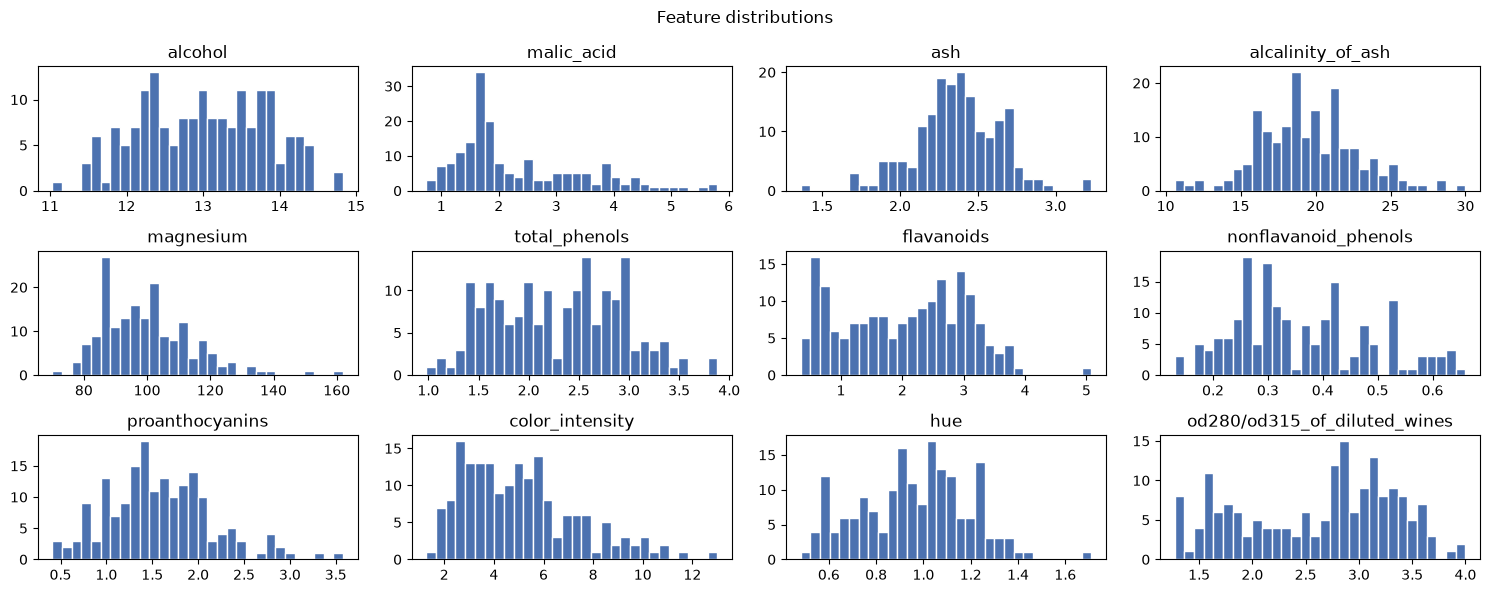

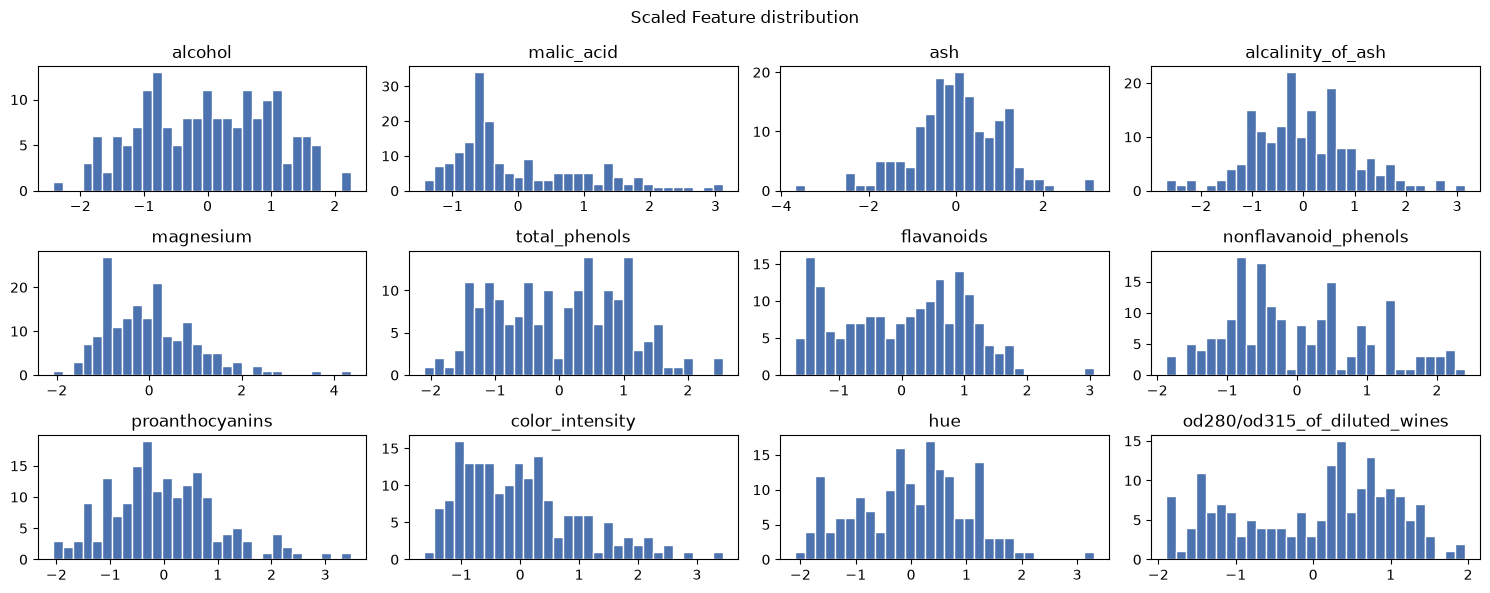

In [16]:
from sklearn.datasets import load_wine
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

wine = load_wine()
X = wine.data.copy()
y = wine.target.copy()
df = pd.DataFrame(X, columns=wine.feature_names)

print("Wine dataset shape:", df.shape)

print("Wine dataset first 5 rows:")
display(df.head())

print("Wine dataset columns:")
display(df.info())

print("Wine dataset description:")
display(df.describe().T)

df_scaled = pd.DataFrame(StandardScaler().fit_transform(df), columns=df.columns)

fig, axes = plt.subplots(3, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), df.columns[:-1]):
    ax.hist(df[col], bins=30, color="#4C72B0", edgecolor="white")
    ax.set_title(col)
fig.suptitle("Feature distributions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), df_scaled.columns[:-1]):
    ax.hist(df_scaled[col], bins=30, color="#4C72B0", edgecolor="white")
    ax.set_title(col)
fig.suptitle("Scaled Feature distribution")
plt.tight_layout()
plt.show()

## Task 2: Checking Elbow and Silhouette K-Means models to optimize k
In this cell I input KMeans and sillhouette score. I then fit KMeans models with k values 1 through 10. I extractes the inertias for each amount of clustering and the sillhouette scores. Then I plotted them showing that k=3 is the elbow of graph and procuces the highest sillhouette score.

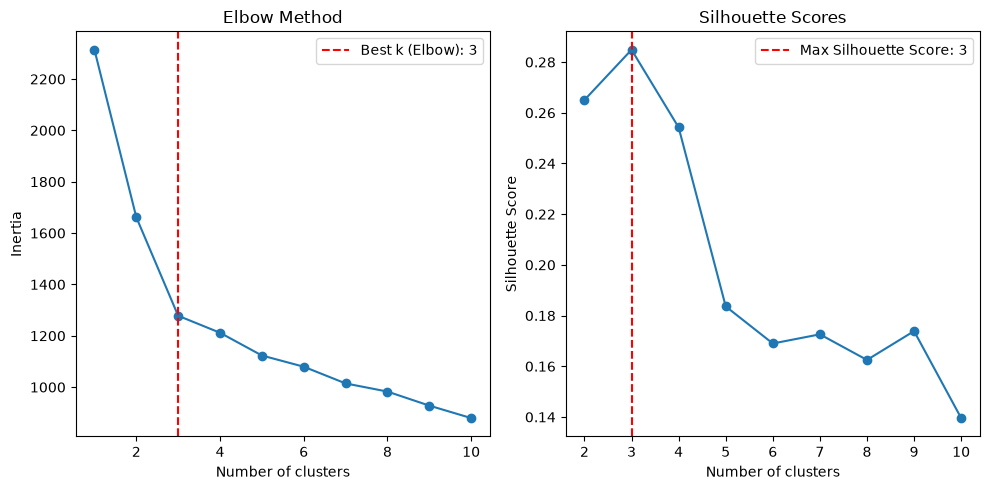

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)
    if k >= 2:
        score = silhouette_score(df_scaled, kmeans.labels_)
        silhouette_scores.append(score)

max_silhouette_score = list(range(2, 11))[int(np.argmax(silhouette_scores))]
best_elbow_k = 3

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].plot(range(1, 11), inertias, marker='o')
ax[0].set_title('Elbow Method')
ax[0].set_xlabel('Number of clusters')
ax[0].set_ylabel('Inertia')
ax[0].axvline(x=best_elbow_k, color='red', linestyle='--', label=f'Best k (Elbow): {best_elbow_k}')
ax[0].legend()

ax[1].plot(range(2, 11), silhouette_scores, marker='o')
ax[1].set_title('Silhouette Scores')
ax[1].set_xlabel('Number of clusters')
ax[1].set_ylabel('Silhouette Score')
ax[1].axvline(x=max_silhouette_score, color='red', linestyle='--', label=f'Max Silhouette Score: {max_silhouette_score}')
ax[1].legend()
plt.tight_layout()
plt.show()

## Task 3: Applying PCA to K-means model using the Voronoi method
In this cell I created a 2-dimensional PCA model and fit a KMeans model to it with k=3. I then applied a mesh grid to the centroids to draw out the voronoi regions. I then displayed the samples and centroids in their respective regions.

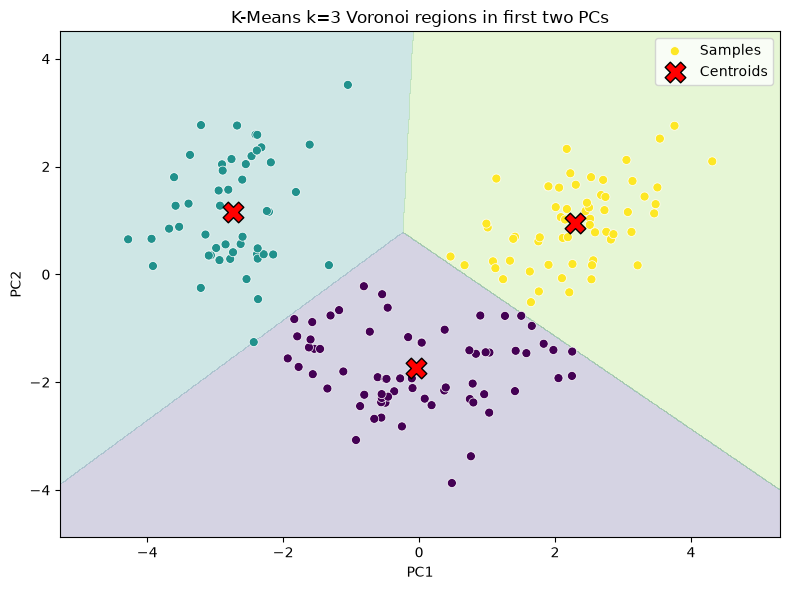

In [18]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(df_scaled)

kmeans = KMeans(n_clusters=best_elbow_k, random_state=42).fit(X_pca)
kmeans_labels = kmeans.labels_

xmin, xmax = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
ymin, ymax = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(xmin, xmax, 0.01), np.arange(ymin, ymax, 0.01))
zz = kmeans.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, alpha=0.22, cmap='viridis', levels=np.arange(-0.5, best_elbow_k + 0.5, 1))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=42, edgecolor='white', linewidth=0.5, label='Samples')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker='X', s=220, c='red', edgecolor='black', label='Centroids')
plt.title(f'K-Means k={best_elbow_k} Voronoi regions in first two PCs')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()

## Task 4: Inspecting Sample to Centroid Profile Differences
This cell fits a 3 k K-Means model on the 13 dimensions. After generating the model I calculated the euclidean distance of 5 distanct samples from the 3 centroids. I then input these values into a heatmap.

c:\Users\kevin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


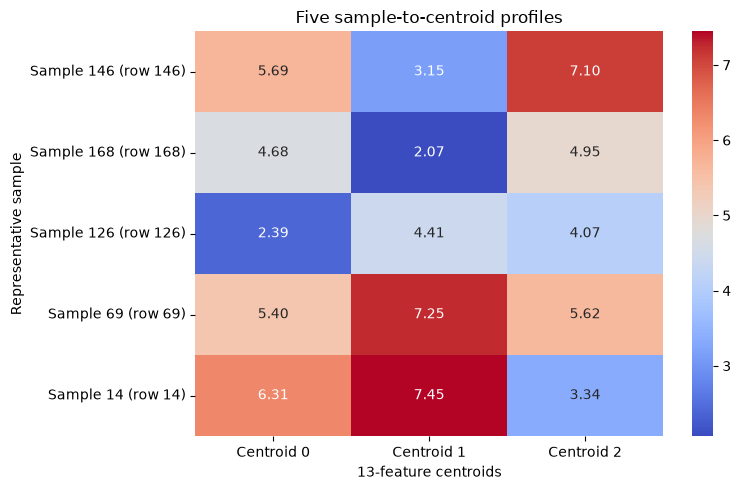

In [19]:
import seaborn as sns

kmeans_13d = KMeans(n_clusters=3, random_state=42)
labels_kmeans = kmeans_13d.fit_predict(df_scaled)

ordered_idx = np.argsort(X_pca[:, 0])
rep_idx = ordered_idx[np.linspace(0, len(ordered_idx) - 1, 5, dtype=int)]
distance_matrix = kmeans_13d.transform(df_scaled.to_numpy()[rep_idx])
row_labels = [f'Sample {i} (row {int(i)})' for i in rep_idx]

fig,ax = plt.subplots(figsize=(8,5))
sns.heatmap(distance_matrix, annot=True, fmt='.2f', cmap='coolwarm', xticklabels=[f'Centroid {i}' for i in range(3)], yticklabels=row_labels, ax=ax)
ax.set_title('Five sample-to-centroid profiles')
ax.set_xlabel('13-feature centroids')
ax.set_ylabel('Representative sample')
plt.tight_layout()
plt.show()

## Task 5: Fitting a DBSCAN and Experimenting with Hyperparameters
In this cell I fit a DBSCAN model using several hyperparameter pairs to see the number of noise points and clusters. The parameters I used were epsilon values 1.5, 2, and 2.5 and minimum samples 3, 5, and 10. I then used the PCA I created before to visualize the model in 2D using hyperparameters eps=2.5 min_samples=10.

DBSCAN with eps=1.5, min_samples=3: 8 clusters, 147 noise points
DBSCAN with eps=1.5, min_samples=5: 0 clusters, 178 noise points
DBSCAN with eps=1.5, min_samples=10: 0 clusters, 178 noise points
DBSCAN with eps=2.0, min_samples=3: 5 clusters, 64 noise points
DBSCAN with eps=2.0, min_samples=5: 5 clusters, 85 noise points
DBSCAN with eps=2.0, min_samples=10: 1 clusters, 139 noise points
DBSCAN with eps=2.5, min_samples=3: 1 clusters, 23 noise points
DBSCAN with eps=2.5, min_samples=5: 1 clusters, 24 noise points
DBSCAN with eps=2.5, min_samples=10: 2 clusters, 32 noise points


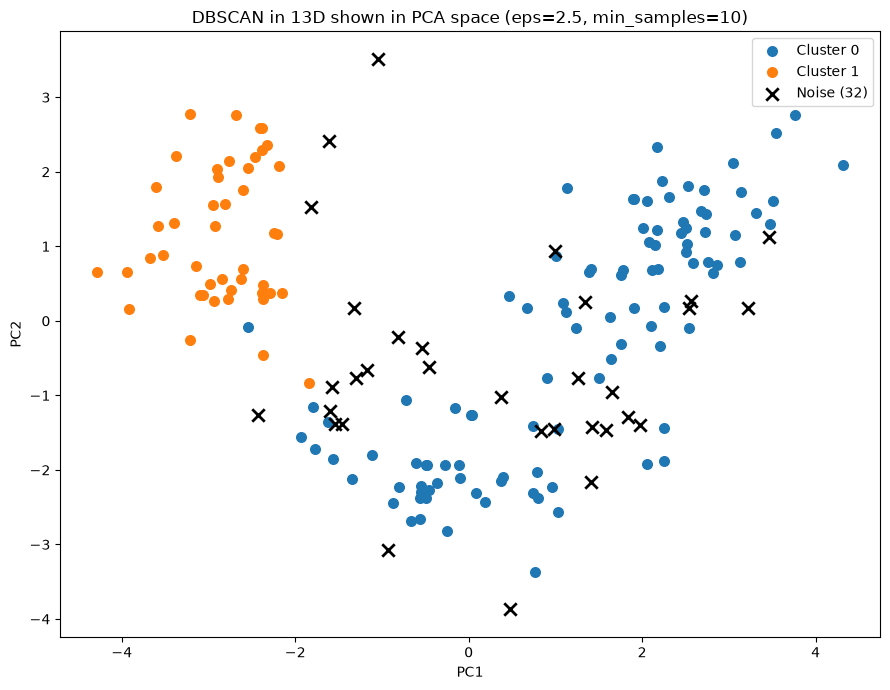

In [20]:
from sklearn.cluster import DBSCAN

eps = [1.5, 2.0, 2.5]
min_samples = [3, 5, 10]

for eps_val in eps:
    for min_samples_val in min_samples:
        dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
        dbscan_labels = dbscan.fit_predict(df_scaled)
        n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
        n_noise = list(dbscan_labels).count(-1)
        print(f"DBSCAN with eps={eps_val}, min_samples={min_samples_val}: {n_clusters} clusters, {n_noise} noise points")

plt.figure(figsize=(9,7))
for label in sorted(set(dbscan_labels) - {-1}):
    mask = dbscan_labels == label
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=48, label=f'Cluster {label}')
plt.scatter(X_pca[dbscan_labels == -1, 0], X_pca[dbscan_labels == -1, 1], marker='x', s=80, linewidth=2, color='black', label=f'Noise ({list(dbscan_labels).count(-1)})')
plt.title(f'DBSCAN in 13D shown in PCA space (eps={eps_val}, min_samples={min_samples_val})')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()

## Task 6: Fitting a HDBSCAN and Reviewing Clusters and Noise
In this cell I imported HDNSCAN and created a model using it. I fit this model with min_samples=5 and found there were 2 clusters and 58 noise points. Then simmilar to the last task I visualized the model using the 2D PCA.

HDBSCAN with 2 clusters, 58 noise points


c:\Users\kevin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


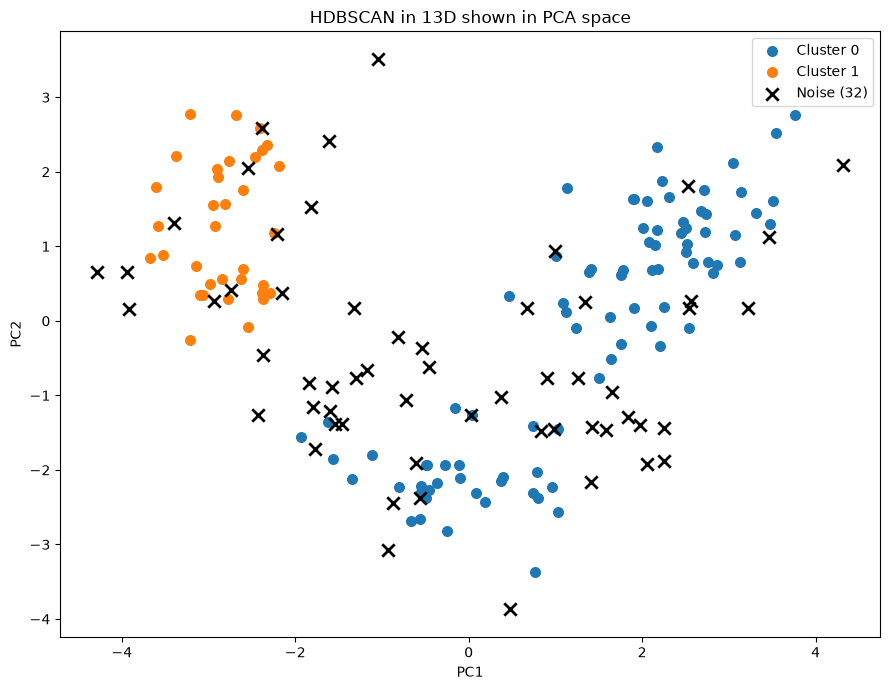

In [21]:
from sklearn.cluster import HDBSCAN

hdbscan = HDBSCAN(min_samples=5)
hdbscan_labels = hdbscan.fit_predict(df_scaled)
n_clusters = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
n_noise = list(hdbscan_labels).count(-1)
print(f"HDBSCAN with {n_clusters} clusters, {n_noise} noise points")

plt.figure(figsize=(9,7))
for label in sorted(set(hdbscan_labels) - {-1}):
    mask = hdbscan_labels == label
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=48, label=f'Cluster {label}')
plt.scatter(X_pca[hdbscan_labels == -1, 0], X_pca[hdbscan_labels == -1, 1], marker='x', s=80, linewidth=2, color='black', label=f'Noise ({list(dbscan_labels).count(-1)})')
plt.title(f'HDBSCAN in 13D shown in PCA space')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()

## Task 7: Computing a Single-Linkage Hierarchical Clustering Matrix
In this cell I used linkage and dendrogram to calculate a single linkage matrix using euclidean distance. I then plotted it to visualize single linkage merge heights.

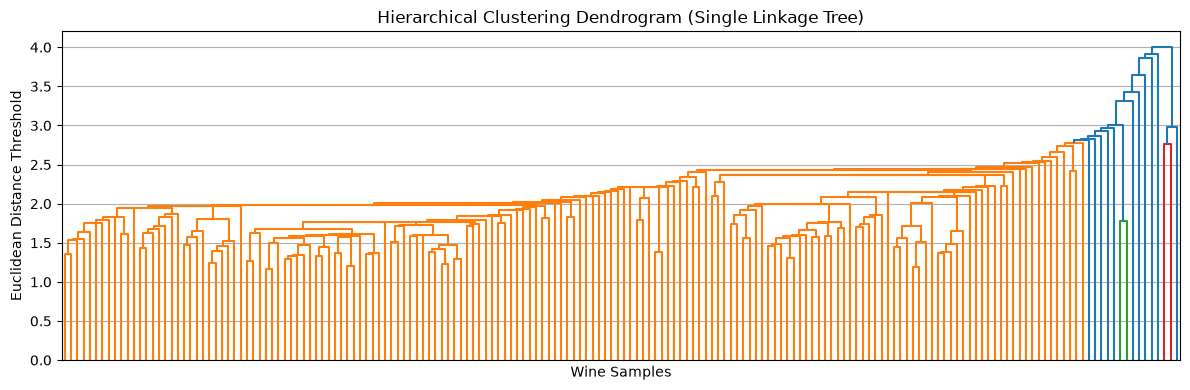

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram

linked = linkage(df_scaled, method='single', metric='euclidean')

plt.figure(figsize=(12, 4))
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=False, no_labels=True)
plt.title('Hierarchical Clustering Dendrogram (Single Linkage Tree)')
plt.xlabel('Wine Samples')
plt.ylabel('Euclidean Distance Threshold')
plt.grid(True)
plt.tight_layout()
plt.show()

## Task 8: Comparing Models on Cultivar Assignment
This code cell takes the cluster outputs of the KMeans, DBSCAN, and HDBSCAN as categorical features, with noise being its own category. I then used a random forest classifier to determine cultivars on a 80/20 training test split on each model. I printed the test accuracy, sillhouette score, noise, and clusters for. I then plotted a bar graph comparing the models on both accuracy and silhouette. This experiment revealed showed in this isntance the KMeans model was the most accurate in classifying, but HDBSCAN had the best overall cluster quality disregarding noise.

c:\Users\kevin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\kevin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\kevin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,Algorithm,Test accuracy,Silhouette (non-noise),Clusters,Noise points
0,K-Means (k=3),0.972,0.285,3,0
1,"DBSCAN (eps=[1.5, 2.0, 2.5])",0.667,0.323,2,32
2,HDBSCAN,0.750,0.352,2,58


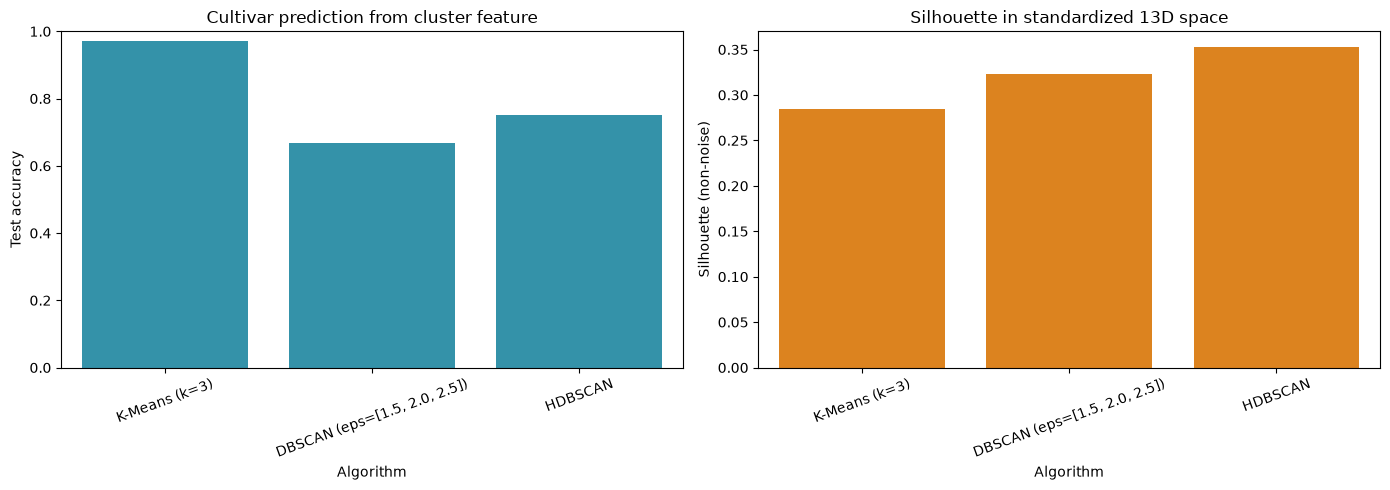

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=.20, random_state=42, stratify=y)
clusterings = {'K-Means (k=3)': labels_kmeans, 
               f'DBSCAN (eps={eps})': dbscan_labels, 
               'HDBSCAN': hdbscan_labels}

def clustering_silhouette(X_data,labels):
    keep = labels != -1
    kept = labels[keep]
    if len(np.unique(kept)) < 2: 
        return np.nan
    
    return silhouette_score(X_data[keep],kept)

results=[]
for name, assignments in clusterings.items():
    encoded = pd.get_dummies(pd.DataFrame({'cluster':assignments.astype(str)}), columns=['cluster'], dtype=int)
    clf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced')
    clf.fit(encoded.iloc[train_idx], pd.DataFrame(y).iloc[train_idx])
    pred = clf.predict(encoded.iloc[test_idx])
    results.append({'Algorithm':name, 
                    'Test accuracy':accuracy_score(pd.DataFrame(y).iloc[test_idx],pred),
                    'Silhouette (non-noise)':clustering_silhouette(df_scaled,assignments),
                    'Clusters':len(set(assignments)-{-1}),
                    'Noise points':int(np.sum(assignments==-1))})

results_df = pd.DataFrame(results)
display(results_df.round(3))

fig,axes = plt.subplots(1, 2, figsize=(14,5))

sns.barplot(data=results_df, x='Algorithm', y='Test accuracy', ax=axes[0], color='#219ebc')
axes[0].set_ylim(0, 1)
axes[0].set_title('Cultivar prediction from cluster feature')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=results_df, x='Algorithm', y='Silhouette (non-noise)', ax=axes[1], color='#fb8500')
axes[1].set_title('Silhouette in standardized 13D space')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()